## **Projeto Meteora**
A Meteora é uma loja de roupas online que busca utilizar seus dados de vendas e estoque para compreender o desempenho do negócio e apoiar decisões estratégicas.

Neste projeto, será realizada uma análise de dados utilizando a linguagem R, com o objetivo de identificar padrões de vendas, produtos mais vendidos e necessidades de reposição de estoque.

Primeiro, vamos ver **como importamos os dados** que a loja nos disponibilizou.

Para isso, faça o upload do arquivo no menu lateral, copie o caminho do arquivo, armazene esse caminho em uma variável e utilize a função read.csv() para ler os dados.

In [ ]:
#Armazenando o caminho do arquivo
path <- '/content/dados_vendas_inventario_meteora_grande.csv'

#Importando os dados
dados_completos <- read.csv(path)

Interpretando o código:


1.   A variável `path` guarda o endereço onde o arquivo CSV está localizado.
2.   A função `read.csv()` utiliza esse caminho para ler o arquivo e armazenar seu conteúdo na variável `dados_completos`, como um *data frame*.



In [ ]:
#Visualizando os dados
head(dados_completos)

,Data,ID_Produto,Nome_Produto,Quantidade_Vendida,Estoque_Disponível,Categoria
,<chr>,<int>,<chr>,<int>,<int>,<chr>
1,2023-01-01,1001,Camisa Social Azul,7,35,Camisas
2,2023-01-01,1002,Calça Jeans,7,58,Calças
3,2023-01-01,1003,Jaqueta de Couro,7,78,Jaquetas
4,2023-01-01,1004,Camisa Social Branca,15,24,Camisas
5,2023-01-01,1005,Saia Longa,7,18,Saias
6,2023-01-01,1006,Blusa de Algodão,8,48,Blusas


Entendendo os argumentos:


1.  `head()`: função utilizada para exibir as primeiras linhas de um objeto.
2.  `dados_completos`: conjunto de dados que será visualizado.

A função `head()` permite conferir rapidamente se a importação foi realizada corretamente e conhecer a estrutura da tabela.

Para verificar se não há nenhum erro de registro que possa influenciar errôneamente nossa análise, usamos a função `summary()`:

In [ ]:
#Verificando os dados
summary(dados_completos)

        Data       ID_Produto      Nome_Produto Quantidade_Vendida
 Length   :310   Min.   :1001   Length   :310   Min.   : 1.00     
 N.unique : 31   1st Qu.:1003   N.unique : 10   1st Qu.: 6.00     
 N.blank  :  0   Median :1006   N.blank  :  0   Median :11.00     
 Min.nchar: 10   Mean   :1006   Min.nchar: 10   Mean   :10.64     
 Max.nchar: 10   3rd Qu.:1008   Max.nchar: 20   3rd Qu.:15.75     
                 Max.   :1010                   Max.   :19.00     
 Estoque_Disponível     Categoria  
 Min.   :10.00      Length   :310  
 1st Qu.:33.00      N.unique :  8  
 Median :54.00      N.blank  :  0  
 Mean   :54.39      Min.nchar:  5  
 3rd Qu.:76.00      Max.nchar:  9  
 Max.   :99.00                     

Com os dados estando corretos, podemos prosseguir para a análise.

## **1. Primeira Demanda: Quantos itens "Camisas" estão registrados na base de dados**
O time de negócios da empresa Meteora solicitou uma análise para identificar **quantos itens de categoria "Camisas" estão registrados na base de dados**. Essa informação será utilizada como apoio no planejamento de futuras campanhas de marketing.

Para isso, vamos inicialmente filtrar dos nossos dados iniciais apenas os itens com categoria "Camisas".

In [ ]:
#Filtrando os dados
dados_camisas <- subset(dados_completos, Categoria == 'Camisas')

#Exibindo os dados filtrados
head(dados_camisas)

,Data,ID_Produto,Nome_Produto,Quantidade_Vendida,Estoque_Disponível,Categoria
,<chr>,<int>,<chr>,<int>,<int>,<chr>
1,2023-01-01,1001,Camisa Social Azul,7,35,Camisas
4,2023-01-01,1004,Camisa Social Branca,15,24,Camisas
11,2023-01-02,1001,Camisa Social Azul,14,86,Camisas
14,2023-01-02,1004,Camisa Social Branca,4,36,Camisas
21,2023-01-03,1001,Camisa Social Azul,2,37,Camisas
24,2023-01-03,1004,Camisa Social Branca,12,44,Camisas


Entendendo os argumentos:
1. `dados_camisas`: variável que armazenará o resultado da filtragem.
2. `subset()`: função utilizada para selecionar parte de um conjunto de dados com base em uma condição.
3. `dados_completos`: base de dados original que será filtrada.
4. `Categoria`: coluna na qual será feita a verificação.
5. `==`: operador de comparação que verifica se dois valores são iguais.
6. `"Camisas"`: valor utilizado como critério de seleção.

Esse bloco cria um **novo dataframe** contendo somente os produtos da categoria "Camisas" e exibe suas primeiras 6 linhas para conferência.

Agora com a filtragem feita, podemos responder a pergunta de negócios, onde procura saber **quantos produtos da categoria "Camisas" estão cadastrados na base de dados:**

In [ ]:
#Armazenando o resultado
quantidade_camisas <- nrow(dados_camisas)

#Exibindo o resultado
quantidade_camisas

[1] 62

Entendendo o argumento:
1. `nrow()`: função que retorna o número total de linhas de um dataframe.

Esse bloco responde diretamente ao questionamento do time de negócios, identificando que **existem 62 registros de produtos na categoria "Camisas"**.

## **2. Segunda Demanda: maior volume de vendas e média de estoque**
Após os resultados positivos da primeira análise, o time de negócios apresentou uma nova solicitação: ampliar o estudo para todos os produtos cadastrados na base.

O objetivo é desenvolver uma estratégia de marketing para a página inicial da empresa, destacando os **produtos com maior volume de vendas** e identificando **a média de estoque desses produtos**. Essas informações servirão de base para orientar as próximas decisões estratégicas.


In [ ]:
#Calculando o total vendido por produto
total_vendido <- aggregate(Quantidade_Vendida ~ Nome_Produto, data=dados_completos, sum)

#Calculando a média de estoque
media_estoque <- aggregate(Estoque_Disponível ~ Nome_Produto, data=dados_completos, mean)

#Agregando os dados
dados_agregados <- merge(total_vendido, media_estoque, by = 'Nome_Produto')

Entendendo os argumentos:


1.  `aggregate()`: **agrupa** dados e realiza cálculos sobre os grupos selecionados.
2. `~`: separa a variável que **será calculada** da variável **utilizada** para agrupar.
3. `Nome_Produto`: coluna que define os **grupos**, ou seja, cada produto.
4. `data = dados_completos`: indica a **base** de dados utilizada.
5. `sum`: função que **soma** as quantidades vendidas de cada produto.
6. `mean`: função que calcula a **média** dos valores de estoque de cada produto.
7. `merge()`: função utilizada para **combinar os dois dataframes**.
8. `by = 'Nome_Produto'`: indica a coluna que será utilizada como referência para unir as tabelas.

**Em resumo**

Esse bloco transforma os dados originais em uma tabela resumida por produto, permitindo comparar o desempenho de vendas e a média de estoque.

Vamos ver o resultado da agregação:

In [ ]:
#Exibindo o resultado
dados_agregados

Nome_Produto,Quantidade_Vendida,Estoque_Disponível
<chr>,<int>,<dbl>
Blusa de Algodão,284,51.87097
Calça de Moletom,378,57.32258
Calça Jeans,321,49.96774
Camisa Social Azul,336,53.16129
Camisa Social Branca,348,60.74194
Camiseta Básica,355,54.06452
Jaqueta de Couro,308,55.64516
Saia Longa,335,51.41935
Terno Completo,275,55.09677


**Interpretando o resultado:**

Entregando a análise para a equipe de negócios da Meteora, que queria saber quais **produtos com maior volume de vendas** e identificando **a média de estoque desses produtos**.

A análise dos dados permite identificar o desempenho de vendas e a média de estoque dos 10 produtos cadastrados na base.

Em relação às vendas, a **Calça de Moletom** apresentou o **maior volume**, com 378 unidades vendidas, seguida pelo *Vestido Floral* (357) e pela *Camiseta Básica* (355). Já o *Terno Completo* registrou o menor volume, com 275 unidades.

Quanto ao estoque médio, a **Camisa Social Branca** apresentou a **maior média**, com aproximadamente 60.74 unidades, enquanto a *Calça Jeans* apresentou a menor, com aproximadamente 49.97 unidades.



> Essa tabela permitirá ao time de negócios analisar quais produtos destacar, quais estão vendendo mais ou menos, e quais desejam impulsionar.


## **3. Terceira Demanda: Indicadores Gerais**

Com os resultados obtidos, surgiu uma nova necessidade: ampliar a análise e obter uma visão geral do desempenho da empresa, sem separar os dados por categoria ou produto.

Dessa vez, o objetivo é calcular **indicadores gerais, como o total de unidades vendidas, a média de vendas, o estoque médio e o desvio padrão.** Essas métricas permitem compreender melhor o comportamento dos dados e identificar características importantes do desempenho da empresa.

Para atender a essa demanda, utilizaremos a função `sapply()`, que permite aplicar uma mesma função a diferentes elementos de uma estrutura de dados, facilitando a execução de vários cálculos de maneira simultânea.

Antes de realizar os cálculos, precisamos selecionar as colunas que contêm as informações que desejamos analisar.

Nesse caso, trabalharemos com `Quantidade_Vendida` e `Estoque_Disponível`, pois elas representam os indicadores que interessam ao time de negócios.

Para isso, utilizaremos a seleção de colunas por meio de um vetor com seus respectivos nomes:

In [ ]:
#Preparando as colunas para análise:
colunas_a_analisar <- dados_completos[ ,c("Quantidade_Vendida", "Estoque_Disponível")]

**Explicação dos elementos:**
- `colunas_a_analisar`: variável que armazenará as colunas selecionadas.
- `dados_completos`: dataframe original.
- `[,]`: permite selecionar linhas e colunas de uma tabela.
- `c()`: cria um vetor com os nomes das colunas desejadas.



> **Importante:**
Em `dados_completos[linhas, colunas]`, o espaço antes da vírgula representa as linhas e o espaço depois representa as colunas.
Ao deixar o primeiro espaço vazio, selecionamos todas as linhas e apenas as colunas indicadas.



Com as colunas selecionadas, podemos **utilizar a função `sapply()` para realizar diferentes cálculos sobre cada uma delas.**

Diferentemente das análises anteriores, não precisamos agrupar os dados por produto ou categoria. Agora, queremos aplicar as mesmas operações a cada coluna selecionada, considerando todos os registros disponíveis.

Para isso, utilizaremos uma função anônima, que permitirá calcular simultaneamente a soma, a média e o desvio padrão de cada coluna.

In [ ]:
#Aplicando a função sapply()
resultado <- sapply(colunas_a_analisar, function(x) c(Soma = sum(x), Média = mean(x), Desvio = sd(x)))

**Explicação dos elementos:**

O funcionamento acontece assim:
1. `sapply()` recebe as colunas armazenadas em `colunas_a_analisar`.
2. `function(x)` recebe uma coluna por vez.
3. `x` representa os valores da coluna que está sendo analisada naquele momento.
4. As funções `sum()`, `mean()` e `sd()` realizam os cálculos de soma, média e desvio padrão, respectivamente, utilizando os valores de `x`.

**Como funciona na prática?**
A função `sapply()` percorre as colunas selecionadas e executa os três cálculos para cada uma delas.

In [ ]:
#Visualizando o resultado:
print(t(round(resultado, 2)))

                    Soma Média Desvio
Quantidade_Vendida  3297 10.64   5.49
Estoque_Disponível 16861 54.39  25.82


Os resultados mostram que a empresa registrou **3.297 unidades vendidas** e apresentou uma **média** de aproximadamente 54 unidades em estoque por registro. Entretanto, os desvios padrão indicam que tanto as vendas quanto os estoques **apresentam variações** ao longo dos registros.

Isso pode ajudar a equipe de negócios a identificar diferenças no comportamento das vendas e na disponibilidade de produtos, contribuindo para decisões mais eficientes sobre reposição e planejamento de estoque.



> O elemento `t()` do código serve para inverter as colunas e a linhas, apenas para facilitar a visualização.



## **4. Quarta Demanda: período de maior procura por Camisas**
A equipe de negócios da Meteora deseja otimizar os investimentos em marketing, direcionando suas campanhas para **os períodos de maior procura por camisas**.

Para isso, precisamos analisar os registros de vendas, **considerando as datas e as quantidades vendidas**. Como já realizamos a filtragem da categoria `Camisas` em uma etapa anterior, podemos reutilizar o DataFrame destinado a isso: `dados_camisas`.

In [ ]:
#Ordenando os produtos com order():
camisas_ordenadas <- dados_camisas[order(dados_camisas$Quantidade_Vendida, decreasing = TRUE), ]


**Entendendo os elementos:**

1. `dados_camisas`: **DataFrame** que contém os registros da categoria Camisas.
2. `order()`: determina a **ordem** dos registros.
3. `dados_camisas$Quantidade_Vendida`: coluna utilizada como **critério** de ordenação.
4. `decreasing = TRUE`: **organiza** os valores do `maior para o menor`.

In [ ]:
#Exibindo os primeiros 6 dados da ordenação:
head(camisas_ordenadas)

,Data,ID_Produto,Nome_Produto,Quantidade_Vendida,Estoque_Disponível,Categoria
,<chr>,<int>,<chr>,<int>,<int>,<chr>
171,2023-01-18,1001,Camisa Social Azul,19,89,Camisas
201,2023-01-21,1001,Camisa Social Azul,18,56,Camisas
301,2023-01-31,1001,Camisa Social Azul,18,72,Camisas
44,2023-01-05,1004,Camisa Social Branca,17,84,Camisas
131,2023-01-14,1001,Camisa Social Azul,17,57,Camisas
214,2023-01-22,1004,Camisa Social Branca,17,79,Camisas


Ao visualizar os primeiros registros, conseguimos identificar quais datas apresentaram os maiores volumes de vendas.

No exemplo, **os maiores valores aparecem em janeiro de 2023**, com destaque para o dia 18, quando foram vendidas 19 unidades de um dos produtos.

Isso nos permite observar quais dias tiveram maior movimentação nas vendas e levantar possíveis oportunidades para campanhas de marketing.

> **Importante:**
A ordenação permite identificar os dias com maiores quantidades vendidas, mas não comprova, por si só, que janeiro foi o mês de maior venda. Para isso, seria necessário agrupar os resultados por mês.

## **5. Quinta Demanda: identificando produtos com estoque baixo**
Depois de analisar as vendas, a equipe da Meteora trouxe uma nova questão, desta vez relacionada à logística.

A empresa deseja identificar **quais produtos da categoria Camisas estão com estoque abaixo de 30 unidades**.

Com essas informações, a equipe poderá acompanhar os produtos que apresentam maior risco de falta de estoque e investigar em quais datas essas situações ocorreram.

In [ ]:
#Filtrando itens com estoque abaixo de 30:
camisas_estoque_baixo <- subset(dados_camisas, Estoque_Disponível < 30)

**Entendendo o código:**
1. `subset(...)`: filtra apenas as linhas do `Estoque_Disponível`, já que o DataFrame `dados_camisas` já filtrou para a gente os itens com a categoria "Camisas".
2. `dados_camisas`: Nosso DataFrame com os dados de todos os produtos de categoria Camisas
5. `Estoque_Disponível < 30`: Seleciona estoques inferiores a 30 unidades.

In [ ]:
#Exibindo o resultado da nossa filtragem:
head(camisas_estoque_baixo)

,Data,ID_Produto,Nome_Produto,Quantidade_Vendida,Estoque_Disponível,Categoria
,<chr>,<int>,<chr>,<int>,<int>,<chr>
4,2023-01-01,1004,Camisa Social Branca,15,24,Camisas
31,2023-01-04,1001,Camisa Social Azul,11,21,Camisas
34,2023-01-04,1004,Camisa Social Branca,9,27,Camisas
51,2023-01-06,1001,Camisa Social Azul,10,26,Camisas
61,2023-01-07,1001,Camisa Social Azul,14,19,Camisas
101,2023-01-11,1001,Camisa Social Azul,13,19,Camisas


**Interpretando o resultado:**
Após executar o código, teremos um novo DataFrame contendo somente os registros de Camisas cujo estoque estava abaixo de 30 unidades.

Esses registros permitem identificar:
- **Produtos**: quais modelos de camisa apresentaram estoque baixo.
- **Datas**: quando essas situações foram registradas.
- **Estoque**: qual era a quantidade disponível em cada ocorrência.
- **Vendas**: quantas unidades foram vendidas naquele dia.

Por exemplo, a Camisa Social Azul apresentou apenas 19 unidades disponíveis em 7 e 11 de janeiro. Isso chama a atenção da equipe de logística, que pode investigar o comportamento desse produto e avaliar a necessidade de reposição.

Dessa forma, a equipe de logística pode identificar produtos que exigem atenção, acompanhar as datas em que o estoque ficou abaixo do limite estabelecido e utilizar essas informações para auxiliar no planejamento de reposição.


## **6. Sexta Demanda: comparar o volume de vendas**
A equipe de negócios da Meteora está avaliando onde concentrar seus investimentos em marketing. Antes de direcionar mais recursos para a categoria Camisas, deseja entender como ela se compara às demais categorias de produtos.

A pergunta principal é:

**Quantas unidades foram vendidas em cada categoria de produtos?**

Com essa informação, poderemos identificar quais categorias apresentam maior volume de vendas e fornecer subsídios para decisões sobre campanhas de marketing.

Primeiramente, precisamos descobrir q**uais categorias estão presentes na base de dados.**

Para isso, utilizaremos a função `unique()`, que retorna os valores sem repetição de uma determinada coluna.

In [ ]:
#Descobrindo quais são as categorias existentes:
categorias <- unique(dados_completos$Categoria)

**Entendendo os elementos:**
1. `unique()`: identifica os valores únicos, eliminando repetições.
2. `dados_completos$Categoria`: acessa a coluna Categoria do DataFrame.

In [ ]:
#Visualizando as categorias existentes no DataFrame original:

categorias

[1] "Camisas"   "Calças"    "Jaquetas"  "Saias"     "Blusas"    "Vestidos" 
[7] "Ternos"    "Camisetas"

Dessa forma, entendemos que a nossa base de dados original possui oito tipos diferentes de categorias: Camisas, Calças, Jaquetas, Saias, Blusas, Vestidos, Ternos e Camisetas.

Agora que conhecemos as categorias, precisamos **preparar um espaço para armazenar o total de vendas de cada uma.**

Para isso, utilizaremos `numeric()` juntamente com `length()`.

In [ ]:
total_vendido_categorias <- numeric(length(categorias))

**Entendendo o código:**
1. total_vendido_categoria: variável que armazenará os totais de vendas.
2. numeric(): cria um vetor numérico inicializado com zeros.
3. length(categorias): informa quantos elementos existem no vetor categorias.

Como identificamos oito categorias, será criado um vetor com oito posições:

In [ ]:
#Saída da nossa variável total_vendido_categorias:

#Perceba que as nossas oito posições estão zeradas. Isso é importante para não haver nenhum erro.
total_vendido_categorias

[1] 0 0 0 0 0 0 0 0

Cada posição será utilizada posteriormente para armazenar o total vendido de uma categoria.

Agora precisamos **percorrer as categorias, calcular suas respectivas quantidades vendidas e armazenar os resultados no vetor criado anteriormente.**

Para isso, utilizaremos um laço de repetição `for`:

In [ ]:
#Calculando as vendas por categorias:
for (i in seq_along(categorias)){
    total_vendido_categorias[i] = sum(dados_completos$Quantidade_Vendida[dados_completos$Categoria == categorias[i]])
}

**Entendendo os elementos:**
1. `for`: Cria um laço de repetição.
2. `i`: Variável que representa a posição atual do laço.
3. `seq_along(categorias)`: Gera uma sequência de posições correspondente aos elementos de categorias.
4. `categorias[i]`: Acessa a categoria da posição atual.
5. `dados_completos$Categoria == categorias[i]`: Seleciona os registros pertencentes à categoria atual.
6. `dados_completos$Quantidade_Vendida`: Acessa as quantidades vendidas.
7. `total_vendido_categoria[i]`: Armazena o resultado na posição correspondente do vetor.

**Como funciona na prática?**

O laço percorre as oito categorias, uma por vez:
1. Identifica a categoria Camisas e soma suas quantidades vendidas.
2. Identifica a categoria Calças e realiza a mesma operação.
3. Repete o processo para Jaquetas, Saias, Blusas, Vestidos, Ternos e Camisetas.

Ao final, cada posição do vetor terá o total de vendas correspondente à categoria de mesma posição no vetor categorias.

In [ ]:
#Visualizando o total calculado das oito categorias:
names(total_vendido_categorias) <- categorias

as.table(total_vendido_categorias)

  Camisas    Calças  Jaquetas     Saias    Blusas  Vestidos    Ternos Camisetas 
      684       699       308       335       284       357       275       355 

Nesse momento, já conseguimos responder à dúvida da empresa. Entretanto, comparar os valores visualmente em uma tabela pode exigir um pouco mais de esforço.

Por isso, vamos **transformar esses resultados em um gráfico.**

Para facilitar a comparação entre as categorias, utilizaremos a função `barplot()`, que cria **gráficos de barras** a partir de valores numéricos.

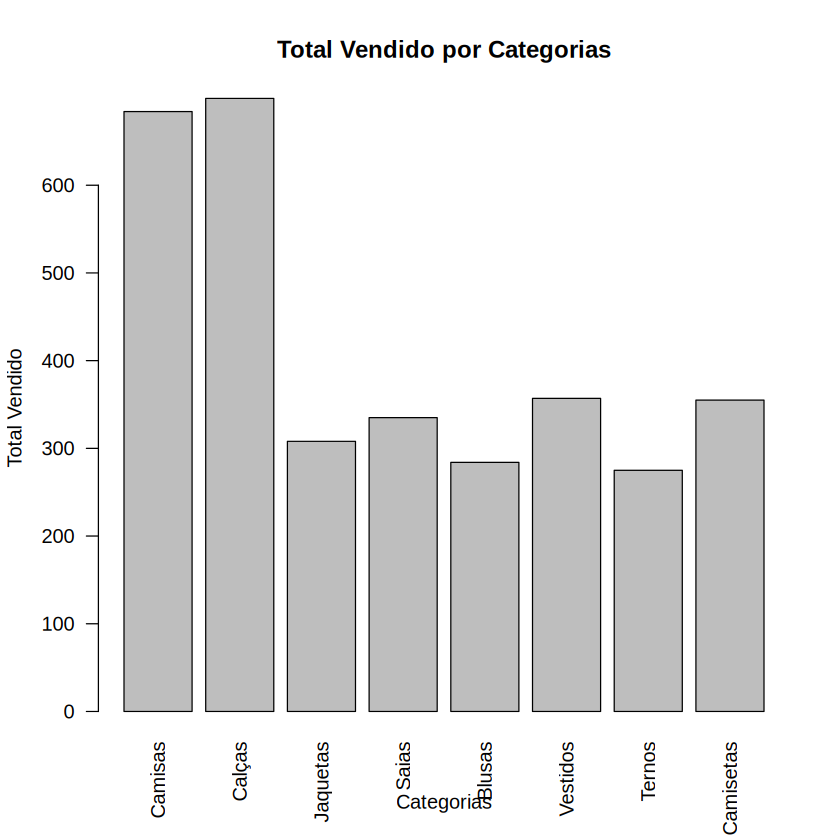

In [ ]:
#Criando um grafico de barras para melhor visualização dos dados:
barplot(total_vendido_categorias,
        names.arg = categorias,
        main = 'Total Vendido por Categorias',
        xlab = 'Categorias',
        ylab = 'Total Vendido',
        las = 2
)

**Entendendo os elementos:**
1. `total_vendido_categoria`: É o que queremos ver no gráfico, os dados que queremos visualizar.
2. `names.arg = categorias`: Identifica cada barra com o nome da categoria correspondente. Nesse caso, estamos nomeando cada barra com o nome da respectiva categoria.
3. `main`: Define o título do gráfico.
4. `xlab`: Define o nome do eixo horizontal (X).
5. `ylab`: Define o nome do eixo vertical (Y).
6. `las = 2`: Deixa os nomes das categorias na vertical, facilitando a leitura.

O resultado será um gráfico em que cada barra representa uma categoria, e sua altura corresponde ao total de unidades vendidas.

**Interpretando o resultado:**
Com o gráfico, conseguimos comparar rapidamente o desempenho das oito categorias.

Podemos destacar alguns pontos:
- **Calças**: apresentam o maior volume de vendas, com 699 unidades.
- **Camisas**: ocupam a segunda posição, com 684 unidades.
- **Ternos**: apresentam o menor volume, com 275 unidades.
- **Blusas**: também possuem um volume relativamente baixo, com 284 unidades.

Um detalhe interessante é que a diferença entre Calças e Camisas é de apenas 15 unidades. Portanto, as duas categorias apresentam volumes de vendas bastante próximos.

Isso indica que Camisas possuem um desempenho expressivo dentro da empresa, **mas não são a categoria mais vendida**.

Para a equipe de marketing, essa comparação pode ajudar a avaliar onde concentrar os investimentos.

## **Etapa Final: armazenamento de dados**
Após realizar as análises solicitadas pela equipe de negócios, surge uma nova necessidade: **armazenar os dados tratados e os resultados das análises** para que possam ser reutilizados futuramente.

A equipe de análise de dados precisa preservar o trabalho realizado, evitando ter que repetir todas as etapas de tratamento e agregação quando surgirem novas demandas.

Para atender a essa necessidade, vamos utilizar duas funções do R: `write.csv()` e `write.table()`.

Primeiro, vamos armazenar o dataframe principal, `dados_completos`, que contém os dados utilizados no projeto.

Também podemos armazenar outros dataframes criados durante as análises, como `dados_agregados` e `dados_camisas`. Assim, preservamos não apenas a base principal, mas também resultados de tratamentos e análises específicas.


In [ ]:
#Armazenando os dados em CSV
write.csv(dados_completos, 'Dados_Completos.csv', row.names = FALSE)

**Entendendo os elementos:**
1. `write.csv()`: exporta os dados para um arquivo CSV.
2. `dados_completos`: dataframe que será armazenado.
3. `"Dados_Completos.csv"`: nome e extensão do arquivo que será criado.
4. `row.names = FALSE`: impede que os índices das linhas sejam adicionados ao arquivo.

Podemos repetir o procedimento para armazenar outros resultados:

In [ ]:
#Armazenando em CSV os dados do DataFrame dados_camisas:
write.csv(dados_camisas, "Dados_Camisas.csv", row.names = FALSE)

#Armazenando em CSV os dados do DataFrame dados_agregados:
write.csv(dados_agregados, "Dados_Agregados.csv", row.names = FALSE)

Nesse caso, teremos três arquivos diferentes, cada um contendo um conjunto de dados relevante para o projeto.

**Interpretação do resultado:**

Após executar os códigos, os arquivos CSV serão gerados no ambiente do Google Colab. Eles poderão ser encontrados na aba lateral de arquivos.

Isso permite preservar:
- A base principal utilizada nas análises.
- Os dados agregados por produto.
- Os registros específicos da categoria Camisas.

> **Importante:**
O armazenamento em CSV não modifica o dataframe original. Ele apenas cria uma cópia dos dados em um arquivo externo.

Outra possibilidade é utilizar a função `write.table()`, que permite exportar dados em formato de tabela e definir o separador entre as informações:

In [ ]:
#Armazenando os dados em TXT:
write.table(dados_completos, file = 'Dados_Completos.txt', row.names = FALSE, col.names = TRUE, sep = '\t')

#Fazendo o mesmo com dados_agregados:
write.table(dados_agregados, file = 'Dados_Agregados.txt', row.names = FALSE, col.names = TRUE, sep = '\t')

#E com dados_camisas:
write.table(dados_camisas, file = 'Dados_Camisas.txt', row.names = FALSE, col.names = TRUE, sep = '\t')

**Entendendo os elementos:**
1. `write.table()`: exporta os dados em formato de tabela.
3. `file =`: define o nome do arquivo, neste caso, "Dados_Completos.txt".
4. `sep = "\t"`: utiliza a tabulação como separador entre as colunas.
5. `col.names = TRUE`: mantém os nomes das colunas no arquivo.
6. `row.names = FALSE`: impede a inclusão dos índices das linhas.

**Interpretação do resultado:**

O arquivo TXT será criado com os dados organizados em colunas separadas por tabulação. A primeira linha apresentará os nomes das variáveis, facilitando a identificação das informações.

O uso de \t é interessante quando queremos evitar possíveis confusões com vírgulas, especialmente em dados que utilizam vírgulas como separadores decimais.

**Como acessar os arquivos no Google Colab?**
Depois de executar os códigos:
1. Acesse a aba **Arquivos**, na lateral esquerda do Colab.
2. Clique no botão de **atualização**.
3. Localize os arquivos gerados.
4. Clique nos três pontos ao lado do arquivo desejado.
5. Selecione **Fazer download**.

Os arquivos armazenados no ambiente temporário do Google Colab podem ser excluídos quando a sessão é encerrada. Por isso, é importante fazer o download e guardar uma cópia em local seguro.

**Interpretação e conclusão da demanda**
Com as funções `write.csv()` e `write.table()`, conseguimos preservar os dados trabalhados durante o projeto em diferentes formatos.

Isso atende à necessidade da equipe de análise de dados, pois permite reutilizar informações já tratadas e resultados previamente calculados, sem precisar reconstruir todo o trabalho desde o início.

É importante lembrar que cada arquivo armazenado representa uma versão dos dados no momento da exportação. Se o dataframe for atualizado posteriormente, será necessário exportá-lo novamente para que o arquivo também contenha as alterações.